In [1]:
import resource_estimation as res
import numpy as np
import matplotlib.pyplot as plt

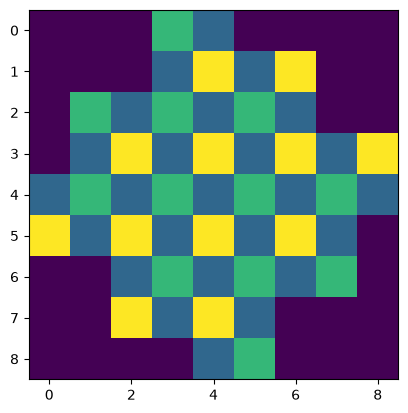

In [2]:
rsc_patch = res.ftqc.codepatch.RotatedSurfaceCodePatch(patch_id=1, d=5)
arr = np.zeros((2*rsc_patch.d-1, 2*rsc_patch.d-1), dtype=int)
for qubit in rsc_patch.default_layout():
    if qubit.role[1] == "X":
        marker = 3
    elif qubit.role[1] == "Z":
        marker = 2
    else:
        marker = 1
    arr[qubit.local_coord] = marker
plt.imshow(arr)
plt.show()

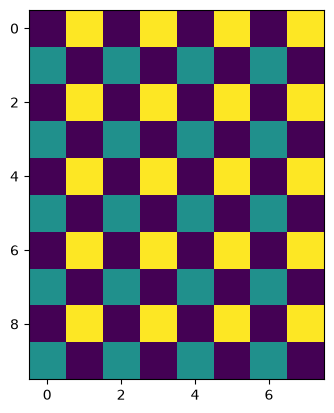

In [3]:
bb_patch = res.ftqc.codepatch.BBCodePatch(patch_id=2, l=4, m=5)
arr = np.zeros((2*bb_patch.qldpc_code.orders[1], 2*bb_patch.qldpc_code.orders[0]), dtype=int)
for qubit in bb_patch.default_layout():
    if qubit.role[1] == "X":
        marker = 3
    elif qubit.role[1] == "Z":
        marker = 2
    else:
        marker = 1
    arr[qubit.local_coord] = marker
plt.imshow(arr)
plt.show()

In [4]:
layout = res.ftqc.codepatch.Layout2(rows=20, cols=20)
ids = (
    layout.add(res.ftqc.codepatch.RotatedSurfaceCodePatch(patch_id=1, d=5), 0, 0),
    layout.add(res.ftqc.codepatch.RotatedSurfaceCodePatch(patch_id=2, d=3), 0, 9),
    layout.add(res.ftqc.codepatch.BBCodePatch(patch_id=3, l=4, m=5), 7, 12),
    layout.add(res.ftqc.codepatch.BBCodePatch(patch_id=4, l=3, m=3), 0, 14),
    layout.add(res.ftqc.codepatch.BBCodePatch(patch_id=5, l=5, m=2), 9, 0),
    layout.add(res.ftqc.codepatch.BBCodePatch(patch_id=6, l=5, m=2), 14, 0),
)

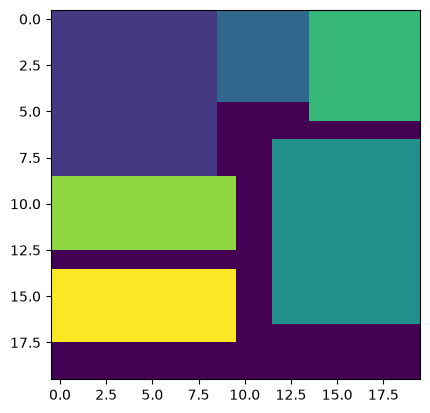

In [5]:
arr = np.zeros((layout.rows, layout.cols), dtype=int)
for pid, p in layout.placements.items():
    for i in range(p.row, p.row_end):
        for j in range(p.col, p.col_end):
            arr[i, j] += pid
plt.imshow(arr)
plt.show()

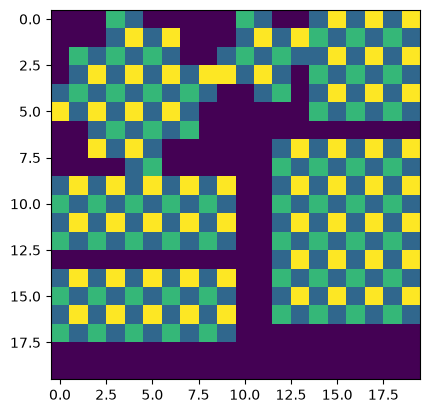

In [6]:
arr = np.zeros((layout.rows, layout.cols), dtype=int)
for pid, p in layout.placements.items():
    for pq in p.element.default_layout():
        if pq.role[1] == "X":
            marker = 3
        elif pq.role[1] == "Z":
            marker = 2
        else:
            marker = 1
        global_row, global_col = layout.global_coord(pid, pq.local_coord)
        arr[global_row, global_col] = marker
plt.imshow(arr)
plt.show()

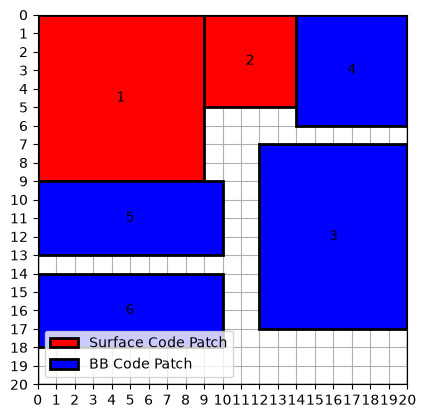

In [7]:
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle, Patch

def get_object_color(obj):
    if isinstance(obj, res.ftqc.codepatch.RotatedSurfaceCodePatch):
        return 'red'
    elif isinstance(obj, res.ftqc.codepatch.BBCodePatch):
        return 'blue'
    elif isinstance(obj, res.ftqc.codepatch.PhysicalQubit):
        if obj.role[1] == "X":
            return "orange"
        elif obj.role[1] == "Z":
            return "gold"
        else:
            return "tomato"
    else:
        raise ValueError("I don't have a color for this object")

def plot_layout_footprints(layout: res.ftqc.codepatch.Layout2):
    fig, ax = plt.subplots()
    ax.add_patch(Rectangle((0, 0), layout.cols, layout.rows, fill=False, linewidth=1))
    for pid, p in layout.placements.items():
        fc = get_object_color(p.element)
        ax.add_patch(Rectangle((p.col, p.row), p.element.footprint.cols, p.element.footprint.rows, alpha=1, edgecolor='black', facecolor=fc, linewidth=2))
        ax.text(p.col + p.element.footprint.cols / 2, p.row + p.element.footprint.rows / 2, str(pid), ha="center", va="center")

    handles = [
        Patch(label="Surface Code Patch", facecolor="red", linewidth=2, edgecolor='black'),
        Patch(label="BB Code Patch", facecolor="blue", linewidth=2, edgecolor='black'),
    ]
    ax.legend(handles=handles)
    ax.set_axisbelow(True)
    ax.set_xlim(0, layout.cols)
    ax.set_ylim(layout.rows, 0)
    ax.grid(True)
    ax.set_aspect("equal")
    ax.set_xticks(range(layout.cols + 1))
    ax.set_yticks(range(layout.rows + 1))
    return fig, ax

fig, ax = plot_layout_footprints(layout)

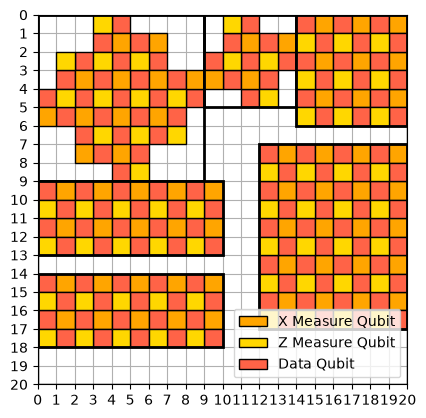

In [8]:
def plot_layout_pqs(layout: res.ftqc.codepatch.Layout2):
    fig, ax = plt.subplots()
    ax.add_patch(Rectangle((0, 0), layout.cols, layout.rows, fill=False, linewidth=1))
    for pid, p in layout.placements.items():
        for pq in p.element.default_layout():
            r, c = layout.global_coord(pid, pq.local_coord)
            fc = get_object_color(pq)
            ax.add_patch(Rectangle((c, r), 1, 1, alpha=1, facecolor=fc, linewidth=1, edgecolor='black', label='yes'))
        ax.add_patch(Rectangle((p.col, p.row), p.element.footprint.cols, p.element.footprint.rows, alpha=1, fill=False, linewidth=2))

    from matplotlib.patches import Patch

    handles = [
        Patch(label="X Measure Qubit", facecolor="orange", linewidth=1, edgecolor='black'),
        Patch(label="Z Measure Qubit", facecolor="gold", linewidth=1, edgecolor='black'),
        Patch(label="Data Qubit", facecolor="tomato", linewidth=1, edgecolor='black'),
    ]
    
    ax.legend(handles=handles)
    ax.set_axisbelow(True)
    ax.set_xlim(0, layout.cols)
    ax.set_ylim(layout.rows, 0)
    ax.grid(True)
    ax.set_aspect("equal")
    ax.set_xticks(range(layout.cols + 1))
    ax.set_yticks(range(layout.rows + 1))
    return fig, ax

fig, ax = plot_layout_pqs(layout)